# Algorithmic Data Science: Week 4 lab - Unit 3 Matrices

## Introduction

One usually uses the numpy library to do matrix manipulations in Python. Let's import that, and create a couple of matrices, as numpy arrays. Here [1,3,4] is the first row of A, [2,-1,0] is the second row, and so on.

In [1]:
import numpy as np

A=np.array([[1,3,4],[2,-1,0],[3,7,9]])
B=np.array([[0,6,1],[-1,-1,5],[3,0,-1]])

print(A)

[[ 1  3  4]
 [ 2 -1  0]
 [ 3  7  9]]


To access an individual component, use indices, starting from 0 (this is different from standard hand-written mathematics, for which indices start from 1).

In [2]:
print(A[0,1])

3


You add matrices just using + (and subtract just using -).

In [3]:
C=A+B
print(C)

[[ 1  9  5]
 [ 1 -2  5]
 [ 6  7  8]]


You can multiply by a scalar like so:

In [4]:
C=5*A
print(C)

[[ 5 15 20]
 [10 -5  0]
 [15 35 45]]


For multiplication you normally use:

In [5]:
C=np.matmul(A,B)
print(C)

[[ 9  3 12]
 [ 1 13 -3]
 [20 11 29]]


However in this lab we're going to use our own functions for implementing the naive method of matrix multiplication and Strassen's method. 

# Helper Import

In [8]:
import sys
from pathlib import Path
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Import your helper module (same setup as Week 3)
root_dir = Path.cwd().parents[1]
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
import aCode.helper as aCode

## Exercise 1

Here is a basic function for implementing the naive method, assuming square matrices are input:

In [6]:
def naivemult(A,B):

    (m,n) = np.shape(A)
        
    C = np.zeros([m,m])
    
    for i in range(m):
        for j in range(m):
            for k in range(m):
                C[i,j] += A[i,k] * B[k,j]
        
    return C

In [7]:
C=naivemult(A,B)
print(C)

[[ 9.  3. 12.]
 [ 1. 13. -3.]
 [20. 11. 29.]]


Repeat the exercise you did last week for the insertion-sort algorithm on the naive matrix multiplication algorithm. I.e., obtain a graph of run time against *n*, for multiplying *n*x*n* matrices, and then do some analyses with your data to demonstrate that the time complexity is $O(n^3)$.

In [ ]:
# Matrix dimensions
sizes = list(range(10, 151, 10))
times_naive = []

np.random.seed(42)

for n in sizes:
    # Generate two random n x n matrices before timing
    A_rand = np.random.randint(1, 100, size=(n, n))
    B_rand = np.random.randint(1, 100, size=(n, n))
    
    t = aCode.timeit(naivemult, A_rand, B_rand, repeats=5)[0]
    times_naive.append(t)

In [11]:
# Log-log transformation
ln_n = [math.log(n) for n in sizes]
ln_t = [math.log(t) for t in times_naive]

# Fit regression line (slicing [2:] skip n=10, 20, too small)
res = stats.linregress(ln_n[2:], ln_t[2:])
alpha = res.slope
ca = math.exp(res.intercept)
fit_line = [alpha * x + res.intercept for x in ln_n]

Estimated alpha (slope): 2.9491 (Expected: ~3.0)
Estimated constant ca:   3.6133e-07 seconds


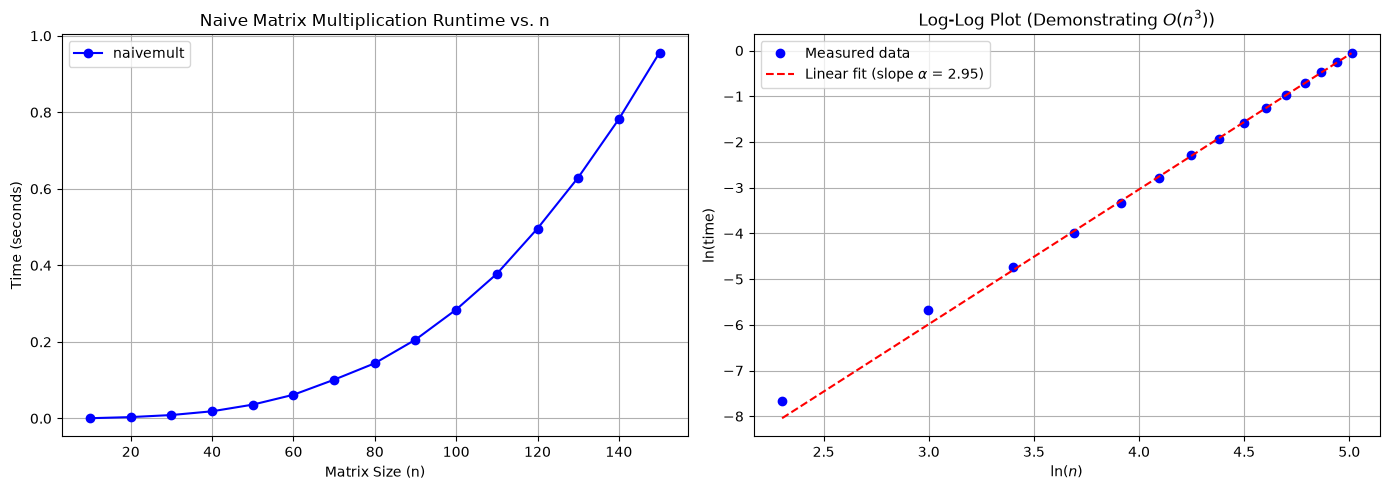

In [12]:
print(f"Estimated alpha (slope): {alpha:.4f} (Expected: ~3.0)")
print(f"Estimated constant ca:   {ca:.4e} seconds")

# Plot both graphs side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw runtime curve (cubic shape)
ax1.plot(sizes, times_naive, 'bo-', label='naivemult')
ax1.set_title('Naive Matrix Multiplication Runtime vs. n')
ax1.set_xlabel('Matrix Size (n)')
ax1.set_ylabel('Time (seconds)')
ax1.grid(True)
ax1.legend()

# Right: Log-log plot with linear fit
ax2.plot(ln_n, ln_t, 'bo', label='Measured data')
ax2.plot(ln_n, fit_line, 'r--', label=f'Linear fit (slope $\\alpha$ = {alpha:.2f})')
ax2.set_title('Log-Log Plot (Demonstrating $O(n^3)$)')
ax2.set_xlabel(r'$\ln(n)$')
ax2.set_ylabel(r'$\ln(\mathrm{time})$')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

Using *np.matmul* is more efficient because it makes use of parallelisation, which we'll discuss in lecture 4, and also runs the for loops in C, so there is less overhead with Python having to repeatedly execute commands in C.

Repeat the exercise using this function to see how much more efficient it is.

> Note: using *np.matmul* instead of our custom `naivemult`.

In [16]:
# Use larger matrix sizes because np.matmul is vastly faster than naivemult
sizes_np = list(range(10, 151, 10))
times_np = []

np.random.seed(42)

for n in sizes_np:
    A_rand = np.random.randint(1, 100, size=(n, n))
    B_rand = np.random.randint(1, 100, size=(n, n))
    
    # Measure mean runtime using your helper module
    t = aCode.timeit(np.matmul, A_rand, B_rand, repeats=10)[0]  # numpy
    times_np.append(t)

In [17]:
# Log-log transformation
ln_n_np = [math.log(n) for n in sizes_np]
ln_t_np = [math.log(t) for t in times_np]

res_np = stats.linregress(ln_n_np[2:], ln_t_np[2:])
alpha_np = res_np.slope
c_np = math.exp(res_np.intercept)
fit_line_np = [alpha_np * x + res_np.intercept for x in ln_n_np]

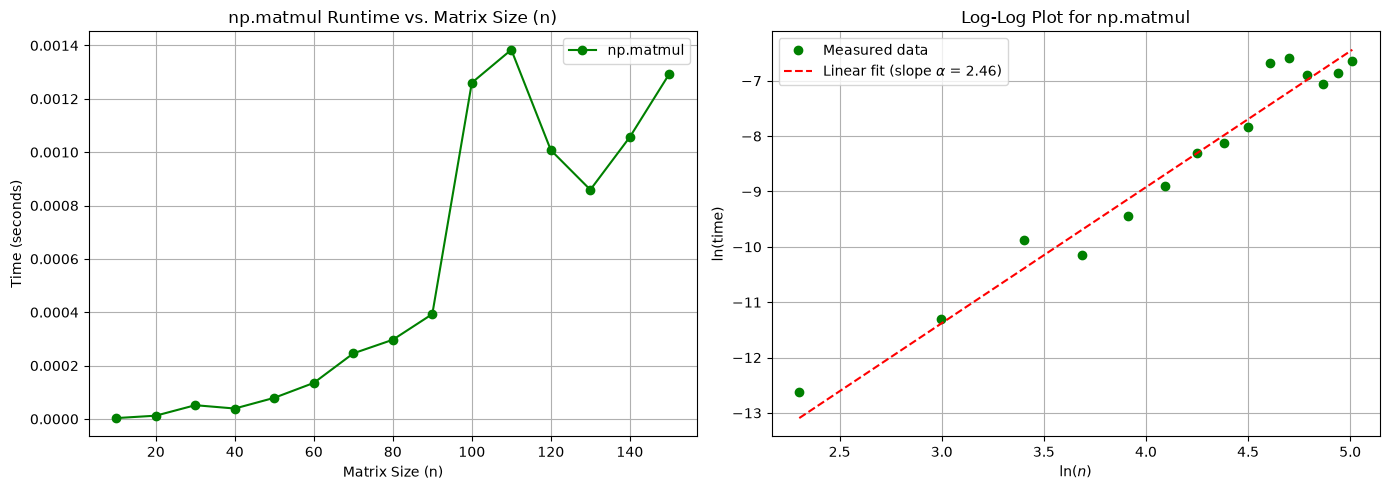

In [18]:
# Plot runtime and log-log fit
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(sizes_np, times_np, 'go-', label='np.matmul')
ax1.set_title('np.matmul Runtime vs. Matrix Size (n)')
ax1.set_xlabel('Matrix Size (n)')
ax1.set_ylabel('Time (seconds)')
ax1.grid(True)
ax1.legend()

ax2.plot(ln_n_np, ln_t_np, 'go', label='Measured data')
ax2.plot(ln_n_np, fit_line_np, 'r--', label=f'Linear fit (slope $\\alpha$ = {alpha_np:.2f})')
ax2.set_title('Log-Log Plot for np.matmul')
ax2.set_xlabel(r'$\ln(n)$')
ax2.set_ylabel(r'$\ln(\mathrm{time})$')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

## Exercise 2

Write a function to implement Strassen's method. (If you are relatively new to Python, just copy and paste this from the solutions, or search for the code on the internet, or use AI to assist you.) You may assume the inputs are square matrices with $n = 2^p$,  where $p$ is a positive integer.

In [19]:
def segment(M):
    (mm,nn)=np.shape(M)
    n = int(mm/2)
    
    a=M[:n,:n]
    b=M[:n,n:]
    c=M[n:,:n]
    d=M[n:,n:]
    
    return (a,b,c,d)


def build(a,b,c,d):
    
    (mm,nn)=np.shape(a)
    C=np.zeros([2*mm,2*mm])
    
    C[:mm,:mm]=a
    C[:mm,mm:]=b
    C[mm:,:mm]=c
    C[mm:,mm:]=d
            
    return C
    

def strassen(M1, M2):

    # base case
    if len(M1) <= 2:
        return naivemult(M1,M2)

    # splitting
    (a,b,c,d) = segment(M1)

    #note: e g f h NOT e f g h 
    (e,g,f,h) = segment(M2)

    P1 = strassen(a, g-h)
    P2 = strassen(a+b, h)
    P3 = strassen(c+d,e)
    P4 = strassen(d,f-e)
    P5 = strassen(a+d,e+h)
    P6 = strassen(b-d,f+h)
    P7 = strassen(a-c,e+g)
    
    r = P5+P4-P2+P6
    s = P1+P2
    t = P3+P4
    u = P5-P3-P7+P1
    
    C = build(r,s,t,u)
    
    return C

In [20]:
E = np.array([[1,2,3,4],[5,6,7,8],[9,10,11,12],[13,14,15,16]])

print(naivemult(E,E))

print(strassen(E,E))

[[ 90. 100. 110. 120.]
 [202. 228. 254. 280.]
 [314. 356. 398. 440.]
 [426. 484. 542. 600.]]
[[ 90. 100. 110. 120.]
 [202. 228. 254. 280.]
 [314. 356. 398. 440.]
 [426. 484. 542. 600.]]



## Strassen's Task 1
- Compare run-times of the naive method and Strassen's method for matrix multiplication.  Consider square matrices where $n = 2^p,  p \in \{1,2,3,\ldots\}$.  To make really big matrices, you could generate random numbers to populate the elements.

- What's the biggest value of $p$ you can use and obtain an output within a couple of minutes? Which method is faster for the largest value of $p$? 

In [25]:
# Test p from 1 to 8 (n = 2 up to n = 256) 
p_values = list(range(1, 10))
sizes_p = [2**p for p in p_values]

times_naive_p = []
times_strassen_p = []

np.random.seed(42)

for p, n in zip(p_values, sizes_p):
    A = np.random.randint(1, 100, size=(n, n))
    B = np.random.randint(1, 100, size=(n, n))
    
    # Fewer repeats for larger matrices so total runtime stays under ~2 minutes
    reps = 10 if p <= 6 else 3
    
    t_naive = aCode.timeit(naivemult, A, B, repeats=reps)[0]
    t_strassen = aCode.timeit(strassen, A, B, repeats=reps)[0]
    
    times_naive_p.append(t_naive)
    times_strassen_p.append(t_strassen)
    
    print(f"p={p} (n={n:3d}) | Naive: {t_naive:.5f}s | Strassen: {t_strassen:.5f}s")

p=1 (n=  2) | Naive: 0.00001s | Strassen: 0.00000s
p=2 (n=  4) | Naive: 0.00003s | Strassen: 0.00005s
p=3 (n=  8) | Naive: 0.00022s | Strassen: 0.00039s
p=4 (n= 16) | Naive: 0.00150s | Strassen: 0.00199s
p=5 (n= 32) | Naive: 0.00935s | Strassen: 0.01257s
p=6 (n= 64) | Naive: 0.07483s | Strassen: 0.08626s
p=7 (n=128) | Naive: 0.62184s | Strassen: 0.61075s
p=8 (n=256) | Naive: 4.74417s | Strassen: 4.34138s
p=9 (n=512) | Naive: 150.34491s | Strassen: 30.81481s


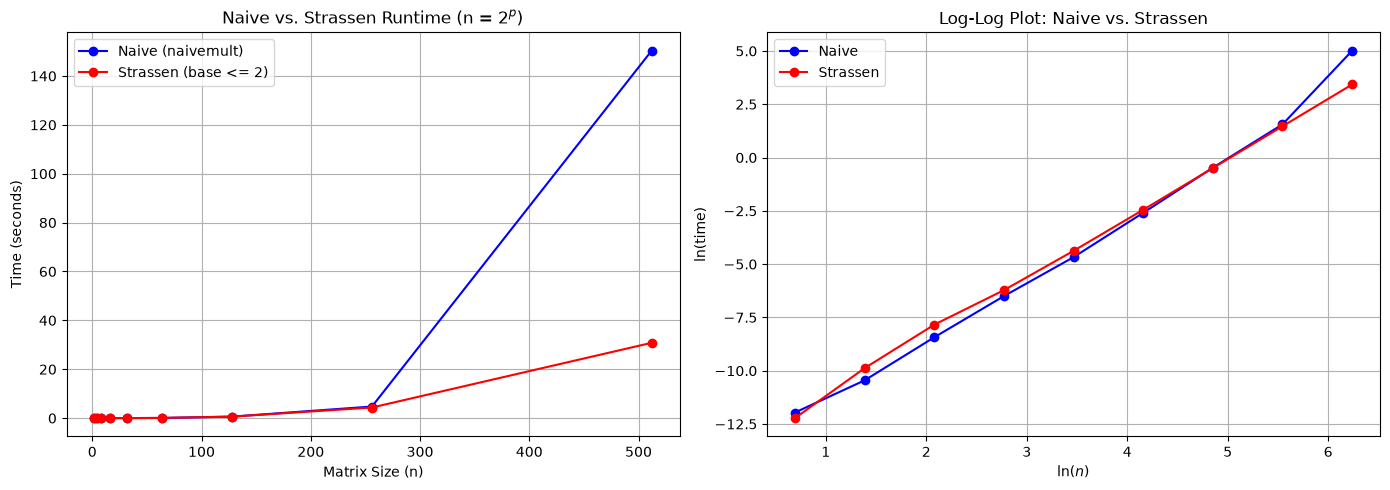

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw runtime vs n
ax1.plot(sizes_p, times_naive_p, 'bo-', label='Naive (naivemult)')
ax1.plot(sizes_p, times_strassen_p, 'ro-', label='Strassen (base <= 2)')
ax1.set_title('Naive vs. Strassen Runtime (n = $2^p$)')
ax1.set_xlabel('Matrix Size (n)')
ax1.set_ylabel('Time (seconds)')
ax1.grid(True)
ax1.legend()

# Right: Log-log plot to compare slopes
ln_n = [math.log(n) for n in sizes_p]
ln_naive = [math.log(t) for t in times_naive_p]
ln_strassen = [math.log(t) for t in times_strassen_p]

ax2.plot(ln_n, ln_naive, 'bo-', label='Naive')
ax2.plot(ln_n, ln_strassen, 'ro-', label='Strassen')
ax2.set_title('Log-Log Plot: Naive vs. Strassen')
ax2.set_xlabel(r'$\ln(n)$')
ax2.set_ylabel(r'$\ln(\mathrm{time})$')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

Theoretically, Strassens has a lower complexity ($2.807$ vs. $3.0$), however, in practice is also results in a massive constant factor $c$ by recursing all the way down to $2 \times 2$ creating millions of Python function calls. This means to realise the complexity gains the input matrices have to be massive themselves, otherwise the constant makes the naive version faster. 

However, we can see at $n=512$, which took several minutes to run, the different between Strassens and the Naive method began to kick in. Timeit suggested that Naive took 150s and Strassen 30s. 

## Strassen's Task 2

Because Strassen's method involves so many additions and subtractions, it is inefficient to use Strassen's method all the way down the recursion. If this is what you've done, then try making a small modification to not do recursion all the way down- instead switch to the naive method once the recursion has broken your large matrix down into matrices of a certain size. Can you then get Strassen's method to beat the naive method?

In [27]:
def strassen_45(M1, M2):

    # base case
    if len(M1) <= 45:
        return naivemult(M1,M2)

    # splitting
    (a,b,c,d) = segment(M1)

    #note: e g f h NOT e f g h 
    (e,g,f,h) = segment(M2)

    P1 = strassen_45(a, g-h)
    P2 = strassen_45(a+b, h)
    P3 = strassen_45(c+d,e)
    P4 = strassen_45(d,f-e)
    P5 = strassen_45(a+d,e+h)
    P6 = strassen_45(b-d,f+h)
    P7 = strassen_45(a-c,e+g)
    
    r = P5+P4-P2+P6
    s = P1+P2
    t = P3+P4
    u = P5-P3-P7+P1
    
    C = build(r,s,t,u)
    
    return C

In [30]:
times_strassen_p_45 = []

np.random.seed(42)

for p, n in zip(p_values, sizes_p):
    A = np.random.randint(1, 100, size=(n, n))
    B = np.random.randint(1, 100, size=(n, n))
    
    # Fewer repeats for larger matrices so total runtime stays under ~2 minutes
    reps = 10 if p <= 6 else 3
    
    # t_naive = aCode.timeit(naivemult, A, B, repeats=reps)[0]
    t_strassen_45 = aCode.timeit(strassen_45, A, B, repeats=reps)[0]
    
    # times_naive_p.append(t_naive)
    times_strassen_p_45.append(t_strassen_45)
    
    print(f"p={p} (n={n:3d}) | Naive: {t_naive:.5f}s | Strassen_45: {t_strassen_45:.5f}s")

p=1 (n=  2) | Naive: 150.34491s | Strassen_45: 0.00001s
p=2 (n=  4) | Naive: 150.34491s | Strassen_45: 0.00003s
p=3 (n=  8) | Naive: 150.34491s | Strassen_45: 0.00026s
p=4 (n= 16) | Naive: 150.34491s | Strassen_45: 0.00171s
p=5 (n= 32) | Naive: 150.34491s | Strassen_45: 0.00987s
p=6 (n= 64) | Naive: 150.34491s | Strassen_45: 0.06579s
p=7 (n=128) | Naive: 150.34491s | Strassen_45: 0.45871s
p=8 (n=256) | Naive: 150.34491s | Strassen_45: 3.23576s
p=9 (n=512) | Naive: 150.34491s | Strassen_45: 22.31835s


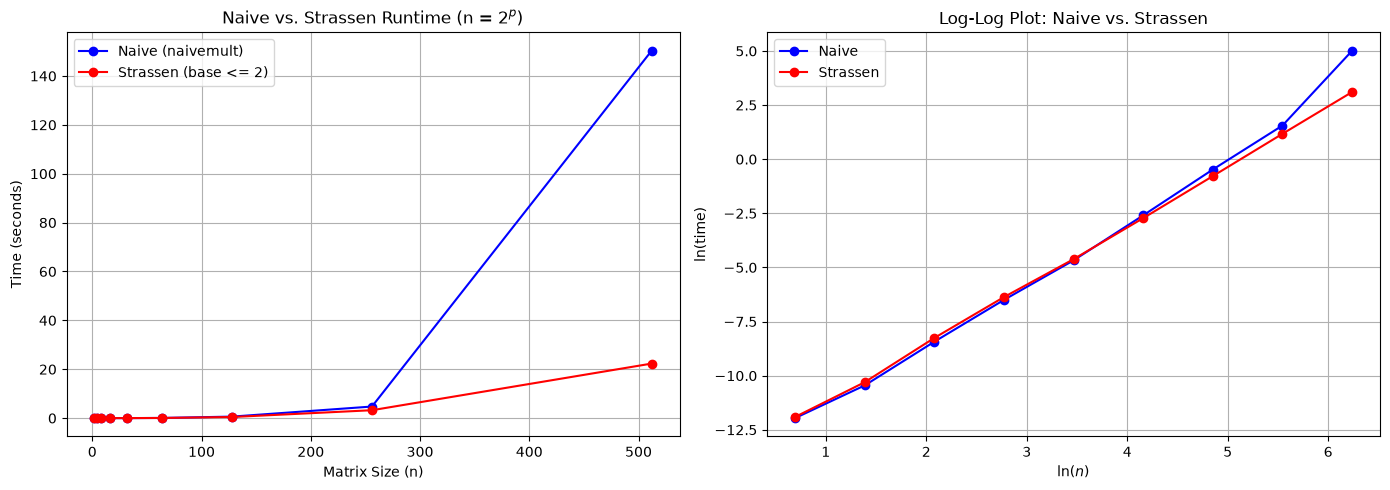

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw runtime vs n
ax1.plot(sizes_p, times_naive_p, 'bo-', label='Naive (naivemult)')
ax1.plot(sizes_p, times_strassen_p_45, 'ro-', label='Strassen (base <= 2)')
ax1.set_title('Naive vs. Strassen Runtime (n = $2^p$)')
ax1.set_xlabel('Matrix Size (n)')
ax1.set_ylabel('Time (seconds)')
ax1.grid(True)
ax1.legend()

# Right: Log-log plot to compare slopes
# ln_n = [math.log(n) for n in sizes_p]
# ln_naive = [math.log(t) for t in times_naive_p]
ln_strassen_45 = [math.log(t) for t in times_strassen_p_45]

ax2.plot(ln_n, ln_naive, 'bo-', label='Naive')
ax2.plot(ln_n, ln_strassen_45, 'ro-', label='Strassen')
ax2.set_title('Log-Log Plot: Naive vs. Strassen')
ax2.set_xlabel(r'$\ln(n)$')
ax2.set_ylabel(r'$\ln(\mathrm{time})$')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

- (Optional) Can you work out how much memory you are using for each method? Is there a way to use less memory?

## Optional extension exercises

- Implement the naive methods of finding determinants and inverses of square matrices.  Can you handle 4x4 or even 5x5 matrices?  What happens to the running time as n gets larger?

- Read up on LUP decomposition, and explore the run-time for finding the inverse of a matrix via LUP decomposition
